# Predicting Galaxy Redshifts from Photometry
## Complete tutorial — Data, physics, baselines, machine learning, and final evaluation
**Author: Dr. Suraj Poudel**  
**Project:** Galaxy Photo-z ML  
**Level:** Familiar with Python; new to machine learning.

**Scientific question:** How well can broadband colors and apparent magnitude predict spectroscopic redshift in a selected SDSS galaxy sample, and where might the predictions fail?

This tutorial connects the computational workflow to the underlying astronomy. We do not yet train a model that learns from photometry. We establish a reproducible pilot dataset and a simple reference prediction against which future models will be compared.

### Learning route
1. Set up Colab and understand reproducibility.
2. Read the SDSS schema and retrieve joined imaging/spectroscopy measurements using SQL.
3. Audit and clean the catalog without losing the original data.
4. Construct colors and separate training, validation, and test galaxies.
5. Interpret the redshift, magnitude, and color distributions physically.
6. Evaluate a training-median baseline on validation galaxies.
7. Save a checkpoint for the next tutorial.

### Working in Colab
Upload this notebook at https://colab.research.google.com/ and save a copy in Drive. Choose a CPU runtime; a GPU is unnecessary. Run code cells in order with Shift+Enter. A notebook saves code, notes, and saved outputs, but runtime variables and files under `/content` can disappear when the session ends. Download the backup at the end, and download the executed notebook separately with **File → Download → Download .ipynb**.

The uploaded source used for this revision contained no stored outputs. No numerical results below are invented. Run the cells to generate your own counts, figures, and scores.

### Vocabulary
| Term | Meaning in this project |
|---|---|
| Feature | A photometric input used to predict redshift |
| Target | Spectroscopic redshift, our reference answer |
| Fit/train | Establish a prediction rule using training examples |
| Validation | Compare model choices on examples excluded from fitting |
| Test | Final evaluation after development decisions are settled |
| Leakage | Information entering model development that should be unavailable |
| Selection function | How observing and catalog rules determine which galaxies enter the sample |

## 0. Prepare the environment
`%pip` installs a Python package into the active notebook environment. `astroquery` provides interfaces to astronomical online services; `astroquery.sdss` handles communication with SDSS. If you see `ModuleNotFoundError: No module named 'astroquery'`, run the installation cell below before the imports. A new Colab runtime may need installation again.

In [ ]:
%pip -q install astroquery

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 70.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 53.7 MB/s eta 0:00:00


### Imports, paths, and reproducibility
The next cell imports our tools and creates project directories.

- `Path` represents filesystem locations; `ROOT` is our Python variable, while `/content` is a real directory in Colab. Defining a path does not itself create a directory.
- `ROOT / folder` constructs a child path. For `Path` objects, `/` joins paths rather than dividing numbers.
- `.mkdir(parents=True, exist_ok=True)` creates missing parent folders and allows the directory to exist already.
- `data` stores catalog files and SQL; `figures` stores plots; `results` stores scores and reproducibility records.
- `metadata.version(...)` records installed package versions. The dictionary comprehension associates each package name with its version.

**What is a seed?** A fixed starting value makes a pseudorandom operation repeatable. With the same data in the same order, `train_test_split(..., random_state=42)` returns the same split. A different integer generally gives a different split; larger seeds do not improve the model. Merely assigning `SEED = 42` does not seed every random operation: it must be passed to the relevant function. For scikit-learn's legacy integer `random_state` convention, valid values run from 0 to $2^{32}-1$. Seed conventions differ between libraries.

If `DummyRegressor` is undefined later, rerun the import below: `from sklearn.dummy import DummyRegressor`. If the runtime restarted, also rerun the cells that create the data and partitions.

In [ ]:
from pathlib import Path
import json, hashlib, platform
from datetime import datetime, timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from astroquery.sdss import SDSS
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor

SEED = 42
ROOT = Path('/content/galaxy-photoz-ml')
for folder in ['data', 'figures', 'results']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
versions = {p: metadata.version(p) for p in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'astroquery', 'astropy']}
print('Python:', platform.python_version())
print(versions)

Python: 3.13.16
{'numpy': '2.1.3', 'pandas': '2.2.3', 'matplotlib': '3.10.0', 'scikit-learn': '1.6.1', 'astroquery': '0.4.11', 'astropy': '7.2.2'}


## 1. Define and retrieve the sample
Use SDSS DR17 Legacy galaxy spectra joined to clean photometry. Restrict to 0.01 < z < 0.3 for a manageable nearby-galaxy pilot. This restriction uses known redshifts to define the study population; the resulting model is not validated for arbitrary galaxies outside it.

`dered_u` through `dered_z` are Galactic-extinction-corrected model magnitudes. The **z-band magnitude** is not **redshift**; we name the latter `z_spec` to prevent confusion.

The checksum ordering creates a repeatable pilot subset. It is not guaranteed to be statistically random, representative, or volume-complete. The query may take a few minutes. Start with 5,000 objects; increase only after this works.

### How SDSS stores the measurements
SDSS provides a catalog database accessed through SkyServer, and separate archive files containing images and spectra. This notebook retrieves **catalog measurements**, not the full spectral arrays or images.

`PhotoObj` and `SpecObj` are table-like **views** into the catalog: photometric detections and selected spectroscopic records, respectively. A row describes a record, while columns describe measurements, identifiers, and flags. Imaging objects without matching spectra cannot supply a spectroscopic training target here.

| View | Fields used here | Role |
|---|---|---|
| `PhotoObj` | `objID`, coordinates, model magnitudes and errors, quality/type flags | Photometry and imaging metadata |
| `SpecObj` | `specObjID`, `bestObjID`, `z`, `zErr`, classification, program, warnings | Reference redshifts and spectroscopy metadata |

These names come from the published **database schema**, not guesses. Consult [DR17 database documentation](https://skyserver.sdss.org/dr17/en/help/docs/docshome.aspx) and [sample queries](https://skyserver.sdss.org/dr17/Support/realquery). A successful query confirms syntax; measurement documentation and sample checks establish scientific meaning.

### Reading our SQL request
SQL means **Structured Query Language**. Its basic form is `SELECT columns FROM table WHERE conditions`. SQL operates on the remote catalog; pandas operates on the returned local data.

| Clause | Meaning in our query |
|---|---|
| `SELECT TOP 5000` | Return at most 5,000 qualifying joined rows |
| `p.objID AS objid` | Return an imaging ID under the output name `objid` |
| `s.z AS z_spec` | Name spectroscopic redshift distinctly from z-band magnitude |
| `FROM PhotoObj AS p` | Use `p` as a short alias for the imaging view |
| `JOIN SpecObj AS s ON s.bestObjID = p.objID` | Match each spectrum to its associated imaging ID |
| `WHERE ... AND ...` | Require every listed condition |
| `ORDER BY ...` | Define the order before applying the row limit |

Plain `JOIN` is an inner join: keep matching records. This resembles `photometry.merge(spectroscopy, left_on='objID', right_on='bestObjID', how='inner')` in pandas. SQL equality uses `=`, rather than Python's `==`. Quoted values such as `'GALAXY'` are strings.

| Condition | Interpretation |
|---|---|
| `s.class = 'GALAXY'` | Spectroscopic classification is galaxy |
| `s.zWarning = 0` | No spectroscopic warning bits set; not an absolute guarantee of a correct redshift |
| `s.survey = 'sdss' AND s.programname = 'legacy'` | Restrict the observing program |
| `p.clean = 1` | Pass the catalog's clean-photometry flag |
| `p.type = 3` | Imaging classification is galaxy |
| `0.01 < s.z < 0.3` | Define our low-redshift pilot population |

`dered_u` through `dered_z` are model magnitudes minus estimated foreground Galactic extinction. They do not correct internal galaxy dust. `modelMagErr_*` are the reported model-magnitude errors; they do not include every possible systematic uncertainty in extinction correction or photometry. Coordinates are in degrees; magnitudes and their errors are in mag; redshift is dimensionless.

**Pilot sampling limitation:** `CHECKSUM(objID, SEED)` produces a deterministic integer, and `objID` breaks ties. This is not a statistical random-number generator, nor a guarantee of representative or uniform sampling. The subset can inherit structure from IDs and the hash. Treat this as a reproducible pilot selection; review it before final science claims. Here `SEED` is a checksum input, not an RNG seed.

**Python versus SQL:** `SQL = f"""..."""` constructs a multiline string. Python replaces `{N_GALAXIES}` and `{SEED}` with their values. `.write_text(SQL)` saves the request for provenance; it does not download data. The next cell executes the request.

In [ ]:
N_GALAXIES = 5000
SQL = f"""
SELECT TOP {N_GALAXIES}
 p.objID AS objid, s.specObjID AS specobjid,
 p.ra, p.dec, s.z AS z_spec, s.zErr AS z_spec_err,
 p.dered_u, p.dered_g, p.dered_r, p.dered_i, p.dered_z,
 p.modelMagErr_u AS err_u, p.modelMagErr_g AS err_g,
 p.modelMagErr_r AS err_r, p.modelMagErr_i AS err_i,
 p.modelMagErr_z AS err_z
FROM PhotoObj AS p
JOIN SpecObj AS s ON s.bestObjID = p.objID
WHERE s.class = 'GALAXY'
 AND s.zWarning = 0
 AND s.survey = 'sdss' AND s.programname = 'legacy'
 AND p.clean = 1 AND p.type = 3
 AND s.z > 0.01 AND s.z < 0.3
ORDER BY CHECKSUM(p.objID, {SEED}), p.objID
"""
(ROOT / 'data/query.sql').write_text(SQL)
print(SQL)


SELECT TOP 5000
 p.objID AS objid, s.specObjID AS specobjid,
 p.ra, p.dec, s.z AS z_spec, s.zErr AS z_spec_err,
 p.dered_u, p.dered_g, p.dered_r, p.dered_i, p.dered_z,
 p.modelMagErr_u AS err_u, p.modelMagErr_g AS err_g,
 p.modelMagErr_r AS err_r, p.modelMagErr_i AS err_i,
 p.modelMagErr_z AS err_z
FROM PhotoObj AS p
JOIN SpecObj AS s ON s.bestObjID = p.objID
WHERE s.class = 'GALAXY'
 AND s.zWarning = 0
 AND s.survey = 'sdss' AND s.programname = 'legacy'
 AND p.clean = 1 AND p.type = 3
 AND s.z > 0.01 AND s.z < 0.3
ORDER BY CHECKSUM(p.objID, 42), p.objID



### Download once, then reuse the saved sample
The next cell follows two branches:

1. If the CSV already exists, read it with pandas.
2. Otherwise, request the catalog rows, convert the returned Astropy Table to pandas, and save a CSV.

`SDSS.query_sql` knows the online service address through Astroquery's SDSS interface; `data_release=17` selects the database release. The SQL string chooses catalogs and records inside that database. `ROOT` and `RAW` only determine the local destination.

| Expression | Purpose |
|---|---|
| `RAW.exists()` | Check for a saved local CSV |
| `dtype={'objid': str, 'specobjid': str}` | Preserve identifiers as text when reading |
| `timeout=180` | Set the request timeout to 180 seconds |
| `cache=True` | Permit reuse of Astroquery's cached response |
| `table is None or len(table) == 0` | Stop clearly if no rows are returned |
| `.to_pandas()` | Convert Astropy Table to DataFrame |
| `.columns.str.lower()` | Standardize column-name capitalization |
| `.astype(str)` | Store IDs as text rather than floating-point measurements |
| `.to_csv(..., index=False)` | Save without an extra pandas index column |
| `.shape` and `.head()` | Inspect dimensions and the first five rows |

Long SDSS IDs must not be rounded through floating-point conversion. Casting an already rounded float to text cannot restore lost digits, so inspect the returned ID types if using a different reader.

**Changing the query:** an existing CSV takes priority over a fresh download. Use a new filename or deliberately remove the old pilot CSV when changing the query, and retain the query that actually generated each dataset. A printed new query does not establish that an old CSV came from it.

In [ ]:
RAW = ROOT / 'data/sdss_dr17_raw.csv'
if RAW.exists():
    df_raw = pd.read_csv(RAW, dtype={'objid': str, 'specobjid': str})
    print('Loaded saved sample:', RAW)
else:
    table = SDSS.query_sql(SQL, data_release=17, timeout=180, cache=True)
    if table is None or len(table) == 0:
        raise RuntimeError('SDSS returned no rows. Check service availability and query.')
    df_raw = table.to_pandas()
    df_raw.columns = df_raw.columns.str.lower()
    # Preserve long catalog IDs as text, never floating-point numbers.
    for name in ['objid', 'specobjid']:
        df_raw[name] = df_raw[name].astype(str)
    df_raw.to_csv(RAW, index=False)
print('Rows and columns:', df_raw.shape)
display(df_raw.head())

Loaded saved sample: /content/galaxy-photoz-ml/data/sdss_dr17_raw.csv
Rows and columns: (5000, 16)


,objid,specobjid,ra,dec,z_spec,z_spec_err,dered_u,dered_g,dered_r,dered_i,dered_z,err_u,err_g,err_r,err_i,err_z
0,1237648722296111346,309742078315751424,160.941521,0.796780,0.122745,0.000012,18.85441,17.73588,17.08761,16.72198,16.52946,0.045313,0.009378,0.007806,0.008627,0.022661
1,1237648722832982256,309722012228544512,160.912011,1.147325,0.118838,0.000033,20.38719,18.48788,17.47920,17.06570,16.72887,0.089066,0.009621,0.006377,0.006580,0.014475
2,1237648721759240421,309730808321566720,160.901399,0.363745,0.082367,0.000018,18.65071,16.77192,15.89387,15.46752,15.13954,0.040086,0.005011,0.003838,0.003810,0.008859
3,1237648722832982245,309722836862265344,160.888077,1.227508,0.106844,0.000017,19.74148,17.84192,16.89196,16.48017,16.18023,0.061371,0.007022,0.004965,0.005125,0.011119
4,1237648721759240426,309743452705286144,160.904757,0.268043,0.081108,0.000018,18.28350,16.27479,15.32262,14.89359,14.55443,0.030565,0.003843,0.002943,0.002911,0.006021


**If the download fails:** do not substitute synthetic data. Retry later or run the printed query at https://skyserver.sdss.org/dr17/SearchTools/sql and export CSV. Upload that CSV using Colab's Files panel, read it with `pd.read_csv(..., dtype={'objid': str, 'specobjid': str})`, lowercase its column names, and save it to `RAW`. Then continue. If the query times out, reduce `N_GALAXIES` to 1000 and rerun the query cells. Keep the successful query with the dataset.

Colab session files are temporary. The last cell downloads a backup.

## 2. Audit before modeling
We remove missing, invalid, or out-of-range measurements using declared rules. The broad magnitude bounds below reject invalid sentinel values; they are not optimized against model performance. Keep a record of every removal. Larger or different samples will need a more careful selection-function analysis.

### Walk through the cleaning code
First we build names using list comprehensions: `[f'dered_{b}' for b in bands]` produces the five magnitude column names. `+` concatenates lists.

`set(required) - set(available)` finds **missing required columns**. Reversing the subtraction finds **extra available columns**, so the two expressions are not interchangeable. `assert not missing` stops if any required column is absent.

We work on `df_raw.copy()` so the downloaded sample remains intact. `pd.to_numeric(..., errors='coerce')` converts numeric text to numbers and invalid text to `NaN`.

| Step | Why it is done |
|---|---|
| `drop_duplicates('objid')` | Keep the first record for each imaging ID |
| `np.isfinite(...).all(axis=1)` | Require every checked numeric entry in a row to be finite |
| Magnitudes between 0 and 35 | Broad screening bounds to reject invalid/sentinel values |
| Magnitude errors between 0 and 5 | Broad screening; not a high-precision-photometry requirement |
| Redshift between 0.01 and 0.3 | Preserve the defined study interval |
| Nonnegative redshift error | Reject invalid reported uncertainties |

`axis=1` checks across columns for each row. `df.loc[mask]` keeps rows marked `True`. `.gt`, `.lt`, and `.ge` mean greater than, less than, and greater than or equal to. `&` combines Boolean masks element by element; `valid &= condition` means `valid = valid & condition`. Parentheses group comparisons correctly.

`reset_index(drop=True)` gives surviving rows a consecutive pandas index; it does not change astronomical IDs. `audit` records the count after each step, making removals visible. `describe().T` displays summary statistics with one measurement per row. The final assertions require at least 200 records and unique imaging IDs; neither establishes scientific completeness or physical uniqueness across different IDs.

**Scientific judgment:** these cuts are declared pilot rules, not universal laws. Negative magnitudes can be physically valid, and uncertainty below 5 mag can still be huge. We require usable u-band measurements even for models where u may contribute little; later we should examine the resulting selection. Outlying colors deserve inspection, not automatic removal because they make prediction harder.

In [ ]:
bands = ['u', 'g', 'r', 'i', 'z']
mag_cols = [f'dered_{b}' for b in bands]
err_cols = [f'err_{b}' for b in bands]
numeric_cols = ['ra', 'dec', 'z_spec', 'z_spec_err'] + mag_cols + err_cols
missing = set(numeric_cols + ['objid', 'specobjid']) - set(df_raw.columns)
assert not missing, f'Missing columns: {missing}'
df = df_raw.copy()
for c in numeric_cols:
    df[c] = pd.to_numeric(df[c], errors='coerce')
audit = {'downloaded': len(df)}
df = df.drop_duplicates('objid').copy()
audit['after_unique_objid'] = len(df)
df = df.loc[np.isfinite(df[numeric_cols]).all(axis=1)].copy()
audit['after_finite_values'] = len(df)
valid = (df[mag_cols].gt(0) & df[mag_cols].lt(35)).all(axis=1)
valid &= (df[err_cols].gt(0) & df[err_cols].lt(5)).all(axis=1)
valid &= df['z_spec'].between(0.01, 0.3, inclusive='neither')
valid &= df['z_spec_err'].ge(0)
df = df.loc[valid].reset_index(drop=True)
audit['after_quality_rules'] = len(df)
assert len(df) >= 200, 'Too few galaxies: inspect the query and audit.'
display(pd.Series(audit, name='rows_remaining'))
display(df[numeric_cols].describe().T)
assert df.objid.is_unique

,rows_remaining
downloaded,5000
after_unique_objid,5000
after_finite_values,5000
after_quality_rules,5000


,count,mean,std,min,25%,50%,75%,max
ra,5000.0,187.466167,57.179012,0.010041,160.345008,177.463555,226.449877,359.995930
dec,5000.0,23.452468,18.786166,-10.998743,7.392938,21.627486,37.960658,66.364295
z_spec,5000.0,0.112364,0.057960,0.010223,0.068280,0.104781,0.146670,0.299089
z_spec_err,5000.0,0.000022,0.000014,0.000002,0.000011,0.000019,0.000029,0.000159
dered_u,5000.0,19.485385,1.088786,14.834750,18.857505,19.505525,20.145243,29.227260
dered_g,5000.0,17.840686,0.864634,13.389320,17.411468,17.993295,18.379677,21.660170
dered_r,5000.0,17.003351,0.787351,12.630300,16.664333,17.186815,17.517335,21.386520
dered_i,5000.0,16.607962,0.783186,12.264520,16.273377,16.784530,17.116847,21.389860
dered_z,5000.0,16.329751,0.808838,11.995210,15.973092,16.480350,16.826722,21.750220
err_u,5000.0,0.088134,0.156315,0.004374,0.037945,0.058911,0.091860,3.254800


## 3. Features and independent partitions
Colors are differences between magnitudes: u−g, g−r, r−i, i−z. Use these four colors plus r-band brightness as the initial features.

Do not use `z_spec`, catalog photo-z estimates, redshift-derived distances, absolute magnitudes, object IDs, or sky position as predictors in this first experiment. Photometric errors are retained for later error analysis.

We reserve 20% for final testing. Of the remaining 80%, one quarter becomes validation: overall proportions are 60% training, 20% validation, 20% test. Explore only the development sample below. A random split is a first benchmark, not evidence of generalization to different survey populations or sky regions.

### Colors: physical inputs, not answers
In an approximately AB-calibrated system,

$$g-r=-2.5\log_{10}(\langle f_\nu\rangle_g/\langle f_\nu\rangle_r).$$

The flux densities are band-averaged quantities, not measurements at single wavelengths. Larger `g_r` means less g-band flux relative to r-band flux. Color describes spectral shape; apparent magnitude additionally carries brightness information. Different stellar populations, dust, emission lines, and redshift can produce overlapping colors.

`zip(bands[:-1], bands[1:])` pairs `(u,g)`, `(g,r)`, `(r,i)`, `(i,z)`. The loop creates four columns by subtracting magnitudes row by row. `FEATURES` stores their names plus `dered_r`; it does not itself fit a model. Four adjacent colors and one magnitude contain the same mathematical information as five magnitudes, before measurement and modeling choices are considered.

Our goal is to learn $z_{\mathrm{pred}}=f(r,u-g,g-r,r-i,i-z)$. `z_spec` is a training **target**, not an input. Using it, or quantities calculated from it such as absolute magnitude or distance, would reveal the answer. Existing photo-z estimates would introduce another prediction model. IDs and coordinates are excluded from this initial photometry-based experiment; coordinates remain useful for a later spatial generalization test.

### Why three independent partitions?
| Partition | Fraction | Role |
|---|---:|---|
| Training | 60% | Learn parameters/prediction rule |
| Validation | 20% | Compare approaches and settings |
| Reserved test | 20% | Evaluate the final chosen approach |

First `train_test_split(df, test_size=0.20)` reserves test rows. Then `train_test_split(dev, test_size=0.25)` assigns one quarter of the remaining 80% to validation: $0.25\times0.8=0.2$. For exactly 5,000 cleaned records this gives 3,000/1,000/1,000; other sizes can involve rounding. Each entire galaxy row stays together.

`dev` combines training and validation. `isdisjoint` verifies there are no shared IDs. Since both train and validation are subsets of dev, checking dev versus test also checks their separation from test.

Explore the development sample, but fit learned preprocessing and model parameters on **training only**. Keeping the test set untouched prevents repeatedly adapting our choices to its answers. A random split provides a benchmark for similar selected records; it does not establish independence from all spatial correlations or performance in other surveys.

In [ ]:
for a, b in zip(bands[:-1], bands[1:]):
    df[f'{a}_{b}'] = df[f'dered_{a}'] - df[f'dered_{b}']
FEATURES = ['dered_r', 'u_g', 'g_r', 'r_i', 'i_z']
dev, test = train_test_split(df, test_size=0.20, random_state=SEED)
train, validation = train_test_split(dev, test_size=0.25, random_state=SEED)
assert set(train.objid).isdisjoint(validation.objid)
assert set(dev.objid).isdisjoint(test.objid)
print('Train / validation / reserved test:', len(train), len(validation), len(test))
print('Features:', FEATURES)
print('Target: z_spec')

Train / validation / reserved test: 3000 1000 1000
Features: ['dered_r', 'u_g', 'g_r', 'r_i', 'i_z']
Target: z_spec


## 3.1 Explore the development sample: plotting and physics
The following cell creates one row of three panels. `fig` represents the whole figure, and `axes[0:3]` represent the panels. `s` controls marker area; `alpha` controls transparency. `.set` assigns axis labels. `sc` stores the third scatter object so the colorbar uses its redshift mapping. `tight_layout` adjusts spacing; `savefig` saves the PNG; `show` displays it.

### Left: redshift distribution
`hist(..., bins=40)` counts galaxies in 40 redshift intervals. Fewer objects at high redshift mean fewer learning examples there, but this is not a census of the Universe. Distances, luminosities, observing rules, redshift cuts, quality screening, and pilot selection all shape this histogram.

### Middle: apparent r magnitude versus redshift
Larger magnitudes mean fainter apparent brightness. A useful schematic relation is

$$m_r=M_r+5\log_{10}(D_L/10\,\mathrm{pc})+K_r(z)+A_{r,\mathrm{internal}},$$

where $M_r$ is an intrinsic dust-free rest-frame magnitude in this convention. Internal dust can instead be incorporated into the definition of $M_r$ and the spectral template used for $K_r$; it must not be counted twice. Foreground Galactic extinction has already been subtracted in `dered_r`.

Distance generally makes a fixed-luminosity galaxy fainter. Intrinsic luminosity differences create scatter. The K correction accounts for comparing different rest-frame spectral regions through fixed observed filters. A brighter apparent galaxy is not automatically closer.

Legacy spectroscopy is not simply one magnitude-limited population. Its main galaxy targeting uses an extinction-corrected **Petrosian** r limit near 17.77, whereas our plotted values are **model** magnitudes. Legacy also includes luminous red galaxy targets selected by color and brightness to greater distances. Do not impose a sharp model-magnitude interpretation on the targeting threshold, or infer intrinsic faintness from the apparent-magnitude trend.

### Right: color–color space with redshift shading
Horizontal and vertical coordinates are observed colors. Dot shading is an artificial code for spectroscopic redshift: purple is lower and yellow is higher. It is not the galaxy's visible photographic color.

“Nearby in color space” means similar numerical colors, not nearby in physical space. Two galaxies with `(g-r,r-i)=(0.80,0.35)` and `(0.82,0.36)` lie close on this plot. Similar shading suggests a statistical color–redshift relationship, but overlap demonstrates degeneracy.

Spectral wavelengths shift as $\lambda_{\mathrm{obs}}=(1+z)\lambda_{\mathrm{rest}}$. The filters stay fixed. For old stellar populations, the 4000 Å break—a broad discontinuity associated largely with accumulated absorption opacity—provides an important feature. Its observed position is 4000, 4400, 4800, and 5200 Å at redshifts 0, 0.1, 0.2, and 0.3. Across this interval it moves through g toward its red edge, changing g/r flux ratios and often increasing g−r for spectra with a strong break.

**Do not attribute both axes solely to that break.** At $z<0.3$ it has not reached the r/i boundary. Continuum curvature, other spectral features, intrinsic populations, dust, and selection influence r−i. A hypothetical featureless $f_\nu\propto\nu^\alpha$ spectrum has redshift-independent colors through fixed filters: redshifting alone does not universally make every color larger. Features and spectral curvature are essential to color-based redshift estimation.

A smooth spectral change with redshift can produce a gradient, but Legacy's color-selected red galaxies can reinforce it. We cannot separate these effects from this diagram alone, and cannot claim that higher-redshift galaxies are universally intrinsically redder. Unusual points below the main sequence warrant inspection of errors, images, and spectra before deciding what they represent.

**Future physics experiment:** redshift one fixed spectrum through the actual filter transmission curves and calculate synthetic colors. This isolates spectral shifting from population changes and survey targeting. It requires proper band integration and wavelength coverage; it is a future investigation, not a result established here.

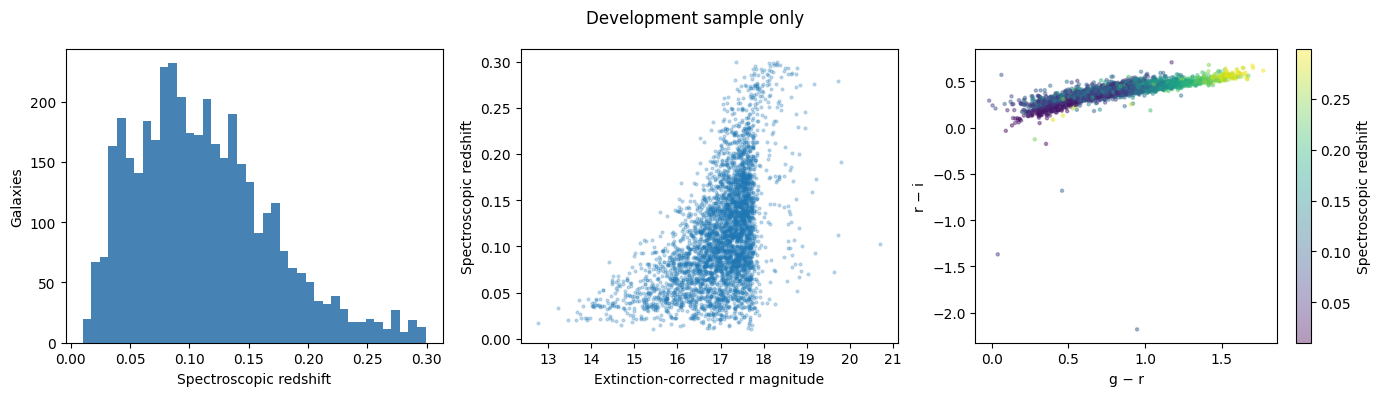

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].hist(dev.z_spec, bins=40, color='steelblue')
axes[0].set(xlabel='Spectroscopic redshift', ylabel='Galaxies')
axes[1].scatter(dev.dered_r, dev.z_spec, s=4, alpha=0.25)
axes[1].set(xlabel='Extinction-corrected r magnitude', ylabel='Spectroscopic redshift')
sc = axes[2].scatter(dev.g_r, dev.r_i, c=dev.z_spec, s=5, alpha=0.4, cmap='viridis')
axes[2].set(xlabel='g − r', ylabel='r − i')
fig.colorbar(sc, ax=axes[2], label='Spectroscopic redshift')
fig.suptitle('Development sample only')
fig.tight_layout()
fig.savefig(ROOT / 'figures/development_overview.png', dpi=180)
plt.show()

## 4. The first baseline
A median baseline ignores the photometry and predicts the training median redshift for every galaxy. It gives a reference to beat.

Let Δz = z_pred − z_spec and δ = Δz/(1+z_spec). Report MAE, RMSE, mean normalized bias, normalized median absolute deviation (NMAD = 1.4826 × median(|δ − median(δ)|)), and a catastrophic-outlier fraction using our declared threshold |δ| > 0.15. This threshold can hide meaningful errors in a low-redshift sample, so always inspect the other metrics too.

Evaluate on **validation**, not the reserved test set. A trained model will learn a relationship between photometry and redshift; this baseline does not.

### Why a baseline, and why these metrics?
Suppose the training median redshift is 0.09. A median baseline predicts 0.09 for every validation galaxy. It may perform reasonably because many galaxies occupy a narrow redshift interval. A learned model must demonstrate improvement over this reference. Among constant predictions, the median minimizes training mean absolute error (the mean minimizes training mean squared error).

For each galaxy define

$$\Delta z=z_{\mathrm{pred}}-z_{\mathrm{spec}},\qquad \delta=\Delta z/(1+z_{\mathrm{spec}}).$$

Positive errors overestimate redshift; negative errors underestimate it. The normalization is relative to the true wavelength stretch factor $1+z$, **not** percentage error in $z$. Our spectroscopic measurement is a reference label with its own uncertainty, not an infallible truth.

| Score | Definition | Interpretation |
|---|---|---|
| MAE | $\mathrm{mean}(|\Delta z|)$ | Average absolute redshift error |
| RMSE | $\sqrt{\mathrm{mean}(\Delta z^2)}$ | Gives large errors more weight |
| Normalized bias | $\mathrm{mean}(\delta)$ | Signed systematic offset; cancellation can conceal scatter |
| NMAD | $1.4826\,\mathrm{median}(|\delta-\mathrm{median}(\delta)|)$ | Robust scatter around median normalized error |
| Outlier fraction | Fraction with $|\delta|>0.15$ | Tail frequency under our declared convention |

The NMAD factor makes median absolute deviation comparable to standard deviation for a Gaussian distribution. A small NMAD alone does not establish small bias. All scores must be interpreted together, and later in redshift/brightness/error bins.

For a true redshift of 0.05 and prediction of 0.10, $\delta=0.05/1.05\simeq0.048$: the redshift doubles, but the 0.15 outlier threshold does not flag it. This conventional threshold can be insensitive in our low-redshift population. Do not interpret a zero outlier fraction as perfect predictions. Avoid treating normalized errors as physical peculiar velocities or distance errors without the appropriate assumptions/cosmological calculation.

### Follow the scoring code
`np.asarray` converts Series or lists to arrays. Their elements must describe the same galaxies in the same order. Arithmetic is elementwise. `np.abs`, `np.mean`, and `np.median` compute magnitudes and summaries. A Boolean outlier mask averages to a fraction because `True` counts as 1 and `False` as 0. `float` converts NumPy results into standard Python numbers for saving.

| Line | Sample and operation |
|---|---|
| `DummyRegressor(strategy='median')` | Construct the reference estimator |
| `.fit(train[FEATURES], train.z_spec)` | Calculate **training** median; photometric values are ignored |
| `.predict(validation[FEATURES])` | Return that same value for each **validation** row |
| `score_redshifts(validation.z_spec, y_pred)` | Calculate **validation** errors |
| `.constant_.item()` | Extract the fitted scalar prediction |
| `pd.DataFrame([metrics], ...)` | Display a one-row score table |

Unlike later models, this estimator does not learn a photometry–redshift relationship. The feature array supplies the standard estimator interface and row count. Validation targets are used to score predictions, not to establish the median. The reserved test sample is untouched.

In [ ]:
def score_redshifts(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    dz = y_pred - y_true
    delta = dz / (1 + y_true)
    return {
        'MAE': float(np.mean(np.abs(dz))),
        'RMSE': float(np.sqrt(np.mean(dz**2))),
        'normalized_bias': float(np.mean(delta)),
        'NMAD': float(1.4826 * np.median(np.abs(delta - np.median(delta)))),
        'outlier_fraction_abs_delta_gt_0.15': float(np.mean(np.abs(delta) > 0.15)),
    }

baseline = DummyRegressor(strategy='median')
baseline.fit(train[FEATURES], train.z_spec)
y_pred = baseline.predict(validation[FEATURES])
metrics = score_redshifts(validation.z_spec, y_pred)
print('Constant prediction:', baseline.constant_.item())
display(pd.DataFrame([metrics], index=['Median baseline: validation']))

Constant prediction: 0.1044996


,MAE,RMSE,normalized_bias,NMAD,outlier_fraction_abs_delta_gt_0.15
Median baseline: validation,0.045411,0.058091,-0.00364,0.051691,0.0


## 5. Save a reproducible checkpoint
The archive includes raw and cleaned CSVs, exact SQL, partitions, an audit, dependency versions, and the plot. Do not commit large datasets to GitHub later; we will supply retrieval instructions and lightweight examples. Download the notebook separately via **File → Download → Download .ipynb** after adding your notes.

### Preserve the analysis between sessions
The next cell saves raw/clean data, the exact query, partition IDs, a development plot, and a JSON record of scores and software versions. The SHA-256 hash fingerprints the raw CSV so later work can verify it uses the same bytes. Recording a timestamp here indicates when the record was written, which may differ from the original retrieval time if a saved CSV was reused.

Saving partition IDs allows future notebooks to reconstruct the same groups instead of accidentally creating a new test set. This cell does not inspect test redshifts or score the test set. `shutil.make_archive` creates a ZIP; `google.colab.files.download` downloads it to your computer. Save it securely with your project files. Download the executed notebook separately so its displayed outputs are retained.

For GitHub, publish the notebook, query, environment instructions, explanatory notes, and compact results. Review dataset size and SDSS acknowledgments before committing catalog files. This notebook is a first milestone, not the completed ML project.

In [ ]:
df.to_csv(ROOT / 'data/sdss_dr17_clean.csv', index=False)
for name, part in [('train', train), ('validation', validation), ('test_reserved', test)]:
    part.objid.to_csv(ROOT / f'data/{name}_ids.csv', index=False)
manifest = {
    'retrieved_or_recorded_utc': datetime.now(timezone.utc).isoformat(),
    'data_release': 17, 'seed': SEED, 'features': FEATURES,
    'target': 'z_spec', 'audit': audit, 'versions': versions,
    'raw_csv_sha256': hashlib.sha256(RAW.read_bytes()).hexdigest(),
    'baseline_validation': metrics,
    'limitations': ['Legacy spectroscopic selection', '0.01 < z_spec < 0.3',
                    'Pilot hash-selected subset', 'Random split only; no spatial test yet'],
}
(ROOT / 'results/notebook01_manifest.json').write_text(json.dumps(manifest, indent=2))
import shutil
archive = shutil.make_archive('/content/galaxy_photoz_milestone01', 'zip', ROOT)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    print('Backup archive:', archive)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 6. Record your results and check your understanding
After executing the notebook, add a Markdown cell with your actual row counts, split sizes, constant prediction, and validation scores. Explain the figures in your own words, distinguishing observation from interpretation. Do not substitute illustrative values for measured outputs.

### Short exercises
1. Why does `required - available` find missing columns, whereas the reverse does not?
2. Explain why changing SQL will not change an already cached local CSV.
3. Expand the color loop into four explicit assignments.
4. What does a larger g−r imply about g/r flux? Is it proof of internal dust?
5. Why does the 4000 Å break help explain g−r more directly than r−i here?
6. Could a redshift–color gradient be strengthened by survey targeting?
7. Why do we fit the median on training data and score it on validation data?
8. How could bias be near zero while RMSE is large?
9. Why can a poor low-redshift prediction escape the 0.15 outlier criterion?
10. What can a random-split score establish, and what would require a separate spatial/survey test?

### Troubleshooting
| Symptom | First check |
|---|---|
| Missing `astroquery` | Run installation, then imports |
| Undefined `DummyRegressor`, `df`, or `train` | Run prerequisite cells in order; runtime variables may have been cleared |
| Empty result or network timeout | Read the query, reduce pilot size if needed, or use the documented CSV fallback |
| Changed query but unchanged sample | Existing local CSV is being reused |
| Missing project files after reopening | `/content` is temporary; restore the backup or rerun |

### Continue the experiment
The following sections now include linear regression, random forests, controlled tuning, feature interpretation, and the completed test evaluation. Read sequentially; the reserved test is opened only after model selection.

## References and provenance
These explanations combine the project's code walkthrough with SDSS documentation. Catalog interpretation and filter physics should always be checked against the relevant release and measurement definitions.

- [SDSS DR17](https://www.sdss4.org/dr17/)
- [Database schema and documentation](https://skyserver.sdss.org/dr17/en/help/docs/docshome.aspx)
- [SDSS example SQL queries](https://skyserver.sdss.org/dr17/Support/realquery)
- [Photometric redshift methodology](https://www.sdss4.org/dr17/algorithms/photo-z/)
- [Legacy targeting: main galaxies and luminous red galaxies](https://www.sdss4.org/dr15/algorithms/legacy_target_selection/) — historical SDSS-I/II selection documentation, relevant to the Legacy program
- [SDSS magnitude calibration](https://www.sdss4.org/dr12/algorithms/fluxcal/)
- [Astroquery SDSS API](https://astroquery.readthedocs.io/en/stable/api/astroquery.sdss.SDSSClass.html)
- [scikit-learn DummyRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyRegressor.html)
- [scikit-learn train_test_split](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html)
- [SQL Server CHECKSUM](https://learn.microsoft.com/en-us/sql/t-sql/functions/checksum-transact-sql)

Include the appropriate [SDSS acknowledgments](https://www.sdss4.org/collaboration/acknowledgements/) and dataset/method citations when preparing the final public repository. This educational pilot is not a claim of a new discovery or validated survey-wide photo-z catalog.

## 7. Learn a relationship: linear regression

We now move from a constant baseline to a model that uses photometry. The previous section completed the first milestone; the remaining sections complete this experiment.

A linear model predicts a weighted combination of the five inputs:

$$\widehat z=b+w_r r+w_{ug}(u-g)+w_{gr}(g-r)+w_{ri}(r-i)+w_{iz}(i-z).$$

`make_pipeline(StandardScaler(), LinearRegression())` joins preprocessing and regression. During `fit`, the scaler learns means and standard deviations **only from training data** and transforms the inputs. Linear regression then learns coefficients by minimizing squared training errors. During `predict`, the same scaler transforms validation inputs without learning anything from them. This prevents preprocessing leakage.

Scaling puts inputs on comparable numerical scales. For ordinary unregularized least squares, it does not add information or fundamentally increase flexibility. The coefficients are empirical relationships in this sample, not physical constants. The five inputs jointly contain the same information as the five magnitudes, because the colors and r magnitude let us reconstruct them.

**Observed result:** validation MAE falls from 0.045411 to 0.021408, a reduction of approximately 53%. RMSE falls from 0.058091 to 0.038040. The learned relationship is useful, but the larger RMSE signals that some errors deserve inspection.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

linear_model = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

linear_model.fit(train[FEATURES], train.z_spec)

linear_predictions = linear_model.predict(validation[FEATURES])

comparison = pd.DataFrame(
    [
        score_redshifts(validation.z_spec, y_pred),
        score_redshifts(validation.z_spec, linear_predictions)
    ],
    index=['Median baseline', 'Linear regression']
)

display(comparison)

,MAE,RMSE,normalized_bias,NMAD,outlier_fraction_abs_delta_gt_0.15
Median baseline,0.045411,0.058091,-0.00364,0.051691,0.000
Linear regression,0.021408,0.038040,0.00138,0.021751,0.002


### 7.1 Inspect individual failures and residuals

`linear_check` keeps each prediction beside its galaxy ID and true redshift. Assigning predictions in the same order as `validation[FEATURES]` preserves alignment. `dz` is the signed redshift error; `delta` normalizes it by $1+z_{\rm spec}$. Sorting `abs(delta)` selects the five largest failures, **not** five randomly selected galaxies.

In the first plot, the dashed identity line marks perfect predictions. In the second, zero marks no error: positive values are overpredictions and negative values are underpredictions. A sloping cloud reveals redshift-dependent bias even when the global mean error is near zero.

Linear regression has no constraint that keeps predictions within our selected redshift range. One validation galaxy has $z_{\rm spec}=0.087012$ but $\widehat z=-0.736119$. Such a prediction is a model failure for this sample. Do not clip predictions or remove failed galaxies before recording the original benchmark.

Predicted redshift range: -0.73611920005059 0.295838874442167
Outliers / validation galaxies: 2 / 1000


,objid,z_spec,dered_r,u_g,g_r,r_i,i_z,z_pred,dz,delta
2839,1237650371563290742,0.087012,16.60577,11.67344,0.94805,-2.18023,3.21595,-0.736119,-0.823131,-0.757242
2786,1237667733968912580,0.050648,17.41207,0.79265,0.03965,-1.36948,0.78921,-0.185243,-0.235891,-0.224520
4204,1237667782823772212,0.212430,16.60896,2.37798,1.03520,0.18709,0.51226,0.074432,-0.137999,-0.113820
2879,1237651752395276335,0.102079,20.70839,2.17579,0.45901,-0.68147,0.78747,-0.017864,-0.119943,-0.108833
3534,1237648705115914384,0.022554,17.35252,1.55730,0.68962,0.37152,0.20338,0.106383,0.083830,0.081981


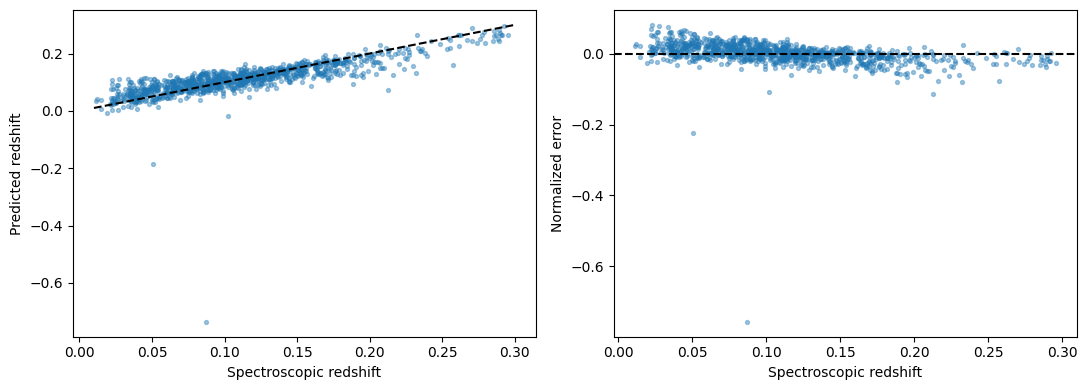

In [ ]:
# Keep each prediction aligned with its validation galaxy.
linear_check = validation[
    ['objid', 'z_spec'] + FEATURES
].copy()

linear_check['z_pred'] = linear_predictions
linear_check['dz'] = (
    linear_check['z_pred'] - linear_check['z_spec']
)
linear_check['delta'] = (
    linear_check['dz'] / (1 + linear_check['z_spec'])
)

print(
    'Predicted redshift range:',
    linear_check.z_pred.min(),
    linear_check.z_pred.max()
)

outliers = linear_check.loc[
    linear_check.delta.abs() > 0.15
]
print('Outliers / validation galaxies:',
      len(outliers), '/', len(linear_check))

display(
    linear_check.loc[
        linear_check.delta.abs()
        .sort_values(ascending=False).head(5).index
    ]
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(
    linear_check.z_spec, linear_check.z_pred,
    s=8, alpha=0.4
)
axes[0].plot([0.01, 0.3], [0.01, 0.3], 'k--')
axes[0].set(
    xlabel='Spectroscopic redshift',
    ylabel='Predicted redshift'
)

axes[1].scatter(
    linear_check.z_spec, linear_check.delta,
    s=8, alpha=0.4
)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(
    xlabel='Spectroscopic redshift',
    ylabel='Normalized error'
)

fig.tight_layout()
plt.show()

### 7.2 Connect failures to the original measurements

The next cell retrieves the original magnitudes and their errors for the same five indices. `.join` aligns by DataFrame index, and `.T` transposes the table so each galaxy becomes a column. Row numbers such as 2839 are DataFrame indices; `objid` is the catalog identifier.

Galaxy 2839 has $u-g=11.67344$, $r-i=-2.18023$, and $i-z=3.21595$: an unusual pattern across bands. Its u and i measurements also have large reported errors. Galaxy 2786 has $r-i=-1.36948$ despite relatively modest errors. These patterns warrant investigation, but the table alone does not establish whether the cause is a measurement problem or an unusual source.

For independent band errors, a useful approximation is

$$\sigma_{a-b}=\sqrt{\sigma_a^2+\sigma_b^2}.$$

For galaxy 2879, $\sigma_{u-g}\approx0.943$ mag. Its colors provide uncertain inputs, yet our regression treats them as fixed values. Correlations between band errors and shared systematic effects can change this approximation. Adjacent colors also share bands, so the color features themselves are correlated.

Galaxy 3534 has precise photometry but a substantial prediction error. Precision alone does not guarantee a unique redshift: stellar populations, dust, and redshift can produce overlapping broad-band colors. The quoted spectroscopic errors for these galaxies are far smaller than the prediction discrepancies.

Our actual cleaning rule is **0 < magnitude error < 5 mag**, not a stringent high-quality selection. All 5,000 downloaded rows survived this audit. That is why passing the filter does not rule out uncertain photometry. Keep these galaxies in the benchmark; any future quality-selection study should be declared separately and compare coverage as well as accuracy.

In [ ]:
# Select the five largest absolute normalized errors.
worst_idx = (
    linear_check['delta']
    .abs()
    .sort_values(ascending=False)
    .head(5)
    .index
)

# Inspect the original magnitudes and their uncertainties.
inspect_cols = (
    ['objid', 'z_spec', 'z_spec_err']
    + mag_cols
    + err_cols
)

diagnostics = validation.loc[worst_idx, inspect_cols].copy()

# Attach predictions and errors using the matching row indices.
diagnostics = diagnostics.join(
    linear_check.loc[worst_idx, ['z_pred', 'dz', 'delta']]
)

display(diagnostics.T)

,2839,2786,4204,2879,3534
objid,1237650371563290742,1237667733968912580,1237667782823772212,1237651752395276335,1237648705115914384
z_spec,0.087012,0.050648,0.21243,0.102079,0.022554
z_spec_err,0.000159,0.000014,0.000092,0.000018,0.000044
dered_u,29.22726,18.24437,20.02214,23.34319,19.59944
dered_g,17.55382,17.45172,17.64416,21.1674,18.04214
dered_r,16.60577,17.41207,16.60896,20.70839,17.35252
dered_i,18.786,18.78155,16.42187,21.38986,16.981
dered_z,15.57005,17.99234,15.90961,20.60239,16.77762
err_u,0.507778,0.046562,0.572327,0.938314,0.072082
err_g,0.033151,0.013399,0.030241,0.089633,0.010242


## 8. A nonlinear model: random forest

A decision tree learns successive feature thresholds, dividing training galaxies into groups. With squared-error regression, a final group (a leaf) predicts the mean training redshift of its members. A random forest averages many trees, each trained on a bootstrap sample drawn **with replacement**. Repeated draws mean some galaxies appear multiple times and others are absent from a particular tree.

The forest can learn different relationships in different regions of brightness and color space. This is useful when a single linear equation is too restrictive. It does not explicitly identify dust, stellar populations, or spectral features; it learns statistical patterns in our selected sample.

| Setting | Meaning in this experiment |
|---|---|
| `n_estimators=300` | Average predictions from 300 trees |
| `min_samples_leaf=5` | Require at least five bootstrap training observations in each leaf |
| `max_features=1.0` | Consider all five features at each split |
| `random_state=SEED` | Reproduce random choices in the same environment |
| `n_jobs=-1` | Use available CPU cores |

No scaling is needed for these threshold-based trees. Predictions are averages of training redshifts and remain within the training target range. This prevents the extreme negative predictions but also limits extrapolation.

**Observed validation result:** MAE = 0.015754, RMSE = 0.021204, NMAD = 0.015121. Relative to linear regression, these decrease by approximately 26%, 44%, and 30%. Zero errors exceed our 0.15 normalized threshold, but meaningful smaller errors remain.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

forest = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=5,
    max_features=1.0,
    random_state=SEED,
    n_jobs=-1,
)

# Learn only from the training sample.
forest.fit(train[FEATURES], train['z_spec'])

# Evaluate on the same validation sample as before.
forest_predictions = forest.predict(validation[FEATURES])

comparison = pd.DataFrame(
    [
        score_redshifts(
            validation['z_spec'],
            baseline.predict(validation[FEATURES])
        ),
        score_redshifts(
            validation['z_spec'],
            linear_predictions
        ),
        score_redshifts(
            validation['z_spec'],
            forest_predictions
        ),
    ],
    index=['Median baseline', 'Linear regression', 'Random forest']
)

display(comparison)

,MAE,RMSE,normalized_bias,NMAD,outlier_fraction_abs_delta_gt_0.15
Median baseline,0.045411,0.058091,-0.00364,0.051691,0.000
Linear regression,0.021408,0.038040,0.00138,0.021751,0.002
Random forest,0.015754,0.021204,0.00208,0.015121,0.000


### 8.1 Read the forest plots

The plotting code converts the reference redshifts to a NumPy array and computes normalized errors in prediction order. Most points follow the identity line more closely than for the linear model. The residual plot still suggests overprediction near the low-redshift boundary and underprediction near the upper boundary.

Averaging nearby training targets can pull predictions inward at sample boundaries. Unequal sampling, ambiguous colors, photometric noise, and model limitations may also contribute. The plot does not isolate those causes. In particular, proximity in color space is a statistical similarity, not physical proximity between galaxies.

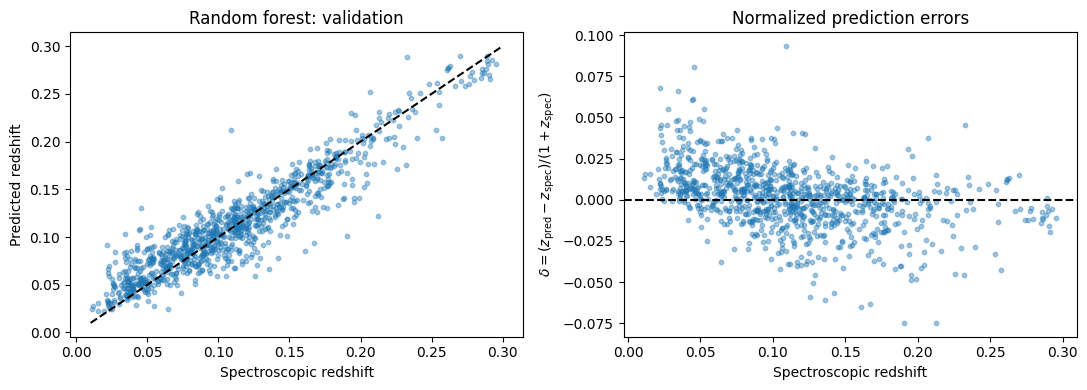

In [ ]:
z_true = validation['z_spec'].to_numpy()
delta_forest = (forest_predictions - z_true) / (1 + z_true)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].scatter(z_true, forest_predictions, s=10, alpha=0.4)
axes[0].plot([0.01, 0.3], [0.01, 0.3], 'k--')
axes[0].set(
    xlabel='Spectroscopic redshift',
    ylabel='Predicted redshift',
    title='Random forest: validation'
)

axes[1].scatter(z_true, delta_forest, s=10, alpha=0.4)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(
    xlabel='Spectroscopic redshift',
    ylabel=r'$\delta = (z_{\mathrm{pred}}-z_{\mathrm{spec}})/(1+z_{\mathrm{spec}})$',
    title='Normalized prediction errors'
)

plt.tight_layout()
plt.show()

### 8.2 Quantify errors by redshift

`pd.cut` assigns galaxies to specified intervals of **true** redshift; `groupby` summarizes each interval. These are evaluation bins, not extra predictors. `observed=True` reports populated categories. Named aggregations create readable output columns, and the small `lambda` computes mean absolute error within each group.

There are 617 validation galaxies between z = 0.05 and 0.15, but only 29 between 0.25 and 0.30. Overall scores therefore emphasize the common population. Mean normalized bias is +0.017516 below 0.05 and becomes negative above 0.10. Median errors have the same general signs, so a few extreme failures do not explain the entire trend.

The first interval may display as `(0.009000000000000001, 0.05]`: this is a pandas display adjustment from `include_lowest=True`, not a change to our original redshift selection. Small bin counts imply less stable summaries.

In [ ]:
# Keep these diagnostics entirely within the validation sample.
forest_check = validation[['z_spec']].copy()
forest_check['z_pred'] = forest_predictions
forest_check['dz'] = (
    forest_check['z_pred'] - forest_check['z_spec']
)
forest_check['delta'] = (
    forest_check['dz'] / (1 + forest_check['z_spec'])
)

# Divide the true redshifts into intervals.
forest_check['redshift_bin'] = pd.cut(
    forest_check['z_spec'],
    bins=[0.01, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30],
    include_lowest=True
)

by_redshift = (
    forest_check
    .groupby('redshift_bin', observed=True)
    .agg(
        galaxies=('delta', 'size'),
        mean_normalized_bias=('delta', 'mean'),
        median_normalized_error=('delta', 'median'),
        MAE=('dz', lambda values: values.abs().mean())
    )
)

display(by_redshift)

,galaxies,mean_normalized_bias,median_normalized_error,MAE
redshift_bin,,,,
"(0.009000000000000001, 0.05]",150,0.017516,0.012552,0.018808
"(0.05, 0.1]",323,0.007009,0.006750,0.014552
"(0.1, 0.15]",294,-0.003788,-0.002724,0.014991
"(0.15, 0.2]",156,-0.007235,-0.003195,0.015878
"(0.2, 0.25]",48,-0.007734,-0.003045,0.019097
"(0.25, 0.3]",29,-0.006839,-0.007009,0.014874


## 9. Model flexibility and generalization

### 9.1 Training versus validation

This cell does not fit a new model. It predicts the training sample using the existing forest and compares scores with validation. Training MAE is 0.011157 and validation MAE is 0.015754, about 41% higher. Some gap is expected because the model learned from training galaxies.

Overfitting means learning training-specific details that do not transfer well. A gap is a diagnostic, not proof of severe overfitting. The relevant question is whether another setting improves held-out accuracy. Do not select the model solely by training error or by the smallest gap.

In [ ]:
# Predictions for galaxies the forest learned from.
forest_train_predictions = forest.predict(train[FEATURES])

train_validation_scores = pd.DataFrame(
    [
        score_redshifts(
            train['z_spec'],
            forest_train_predictions
        ),
        score_redshifts(
            validation['z_spec'],
            forest_predictions
        ),
    ],
    index=['Random forest: training', 'Random forest: validation']
)

display(train_validation_scores)

,MAE,RMSE,normalized_bias,NMAD,outlier_fraction_abs_delta_gt_0.15
Random forest: training,0.011157,0.015974,0.000246,0.010277,0.0
Random forest: validation,0.015754,0.021204,0.002080,0.015121,0.0


### 9.2 A controlled tuning experiment

We change only `min_samples_leaf`, keeping the features, partitions, tree count, and seed fixed. Small leaves permit detailed relationships; large leaves smooth over more galaxies and can lose useful information. This is an empirical balance between flexibility and averaging, not a direct measurement of physical complexity.

`forest_candidates` stores each fitted model under its leaf size. `leaf_results` collects dictionaries that pandas turns into a comparison table. We reuse the existing size-5 model. Our declared primary selection metric is **validation MAE**; other metrics expose tradeoffs.

Size 1 yields validation MAE 0.015629 versus 0.015754 for size 5, only about 0.8% better. Sizes 10 and 20 perform worse. Size 1 has a larger training–validation gap but better held-out accuracy. A single split does not establish a reliable advantage.

In [ ]:
leaf_results = []
forest_candidates = {}

for leaf_size in [1, 5, 10, 20]:
    # Reuse the forest we already trained when leaf_size = 5.
    if leaf_size == 5:
        candidate = forest
    else:
        candidate = RandomForestRegressor(
            n_estimators=300,
            min_samples_leaf=leaf_size,
            max_features=1.0,
            random_state=SEED,
            n_jobs=-1,
        )
        candidate.fit(train[FEATURES], train['z_spec'])

    forest_candidates[leaf_size] = candidate

    train_pred = candidate.predict(train[FEATURES])
    val_pred = candidate.predict(validation[FEATURES])

    train_scores = score_redshifts(train['z_spec'], train_pred)
    val_scores = score_redshifts(validation['z_spec'], val_pred)

    leaf_results.append({
        'min_samples_leaf': leaf_size,
        'train_MAE': train_scores['MAE'],
        'validation_MAE': val_scores['MAE'],
        'validation_RMSE': val_scores['RMSE'],
        'validation_NMAD': val_scores['NMAD'],
        'validation_bias': val_scores['normalized_bias'],
    })

leaf_comparison = pd.DataFrame(leaf_results).set_index(
    'min_samples_leaf'
)

display(leaf_comparison)

,train_MAE,validation_MAE,validation_RMSE,validation_NMAD,validation_bias
min_samples_leaf,,,,,
1,0.006107,0.015629,0.021157,0.014622,0.002255
5,0.011157,0.015754,0.021204,0.015121,0.002080
10,0.013684,0.016223,0.021757,0.016151,0.002070
20,0.015725,0.017068,0.022846,0.017211,0.002200


### 9.3 Five-fold cross-validation, step by step

We divide **the original 3,000 training galaxies into five groups**, not four. In each round, a fresh forest trains on four groups (2,400 galaxies) and is scored on the remaining group (600 galaxies).

| Round | Training groups | Evaluation group |
|---|---|---|
| 1 | B, C, D, E | A |
| 2 | A, C, D, E | B |
| 3 | A, B, D, E | C |
| 4 | A, B, C, E | D |
| 5 | A, B, C, D | E |

`KFold` defines the shared shuffled partitions. `clone` copies estimator settings without fitted state; `cross_val_score` fits separate models for the folds. Scikit-learn uses negative MAE because larger scores are considered better; the leading minus sign restores positive errors. The outer folds run sequentially while each forest uses CPU cores internally.

Size 1 wins four of five folds. Mean MAE is 0.016678 versus 0.016796 for size 5, a small 0.7% difference. Size 5 varies slightly less between folds. We select size 1 while documenting that the alternatives are similar; no statistical significance claim follows from this table.

The original validation and test samples are absent from these folds. Because the candidates were shortlisted using validation results, this cross-validation is a supporting diagnostic, not an independent unbiased assessment of the whole selection procedure. The final reserved test provides that assessment for this random split. Fold standard deviation is not an individual galaxy uncertainty or a confidence interval on mean performance.

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import KFold, cross_val_score

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_results = []

for leaf_size in [1, 5]:
    candidate = clone(forest_candidates[leaf_size])

    # Run folds sequentially; each forest uses available CPU cores.
    fold_mae = -cross_val_score(
        candidate,
        train[FEATURES],
        train['z_spec'],
        scoring='neg_mean_absolute_error',
        cv=cv,
        n_jobs=1,
    )

    cv_results.append({
        'min_samples_leaf': leaf_size,
        **{
            f'fold_{i + 1}_MAE': value
            for i, value in enumerate(fold_mae)
        },
        'mean_MAE': fold_mae.mean(),
        'std_MAE': fold_mae.std(ddof=1),
    })

cv_comparison = pd.DataFrame(cv_results).set_index(
    'min_samples_leaf'
)

display(cv_comparison)

,fold_1_MAE,fold_2_MAE,fold_3_MAE,fold_4_MAE,fold_5_MAE,mean_MAE,std_MAE
min_samples_leaf,,,,,,,
1,0.016921,0.016772,0.015549,0.016400,0.017748,0.016678,0.000801
5,0.016988,0.017100,0.015772,0.016571,0.017548,0.016796,0.000670


## 10. Which features does the model rely on?

Permutation importance shuffles one validation feature among galaxies and measures the increase in MAE. The other inputs remain fixed. Repeating 20 times shows sensitivity to the random shuffles. The selected forest is already fitted on training; importance does not retrain it.

Shuffling g−r increases MAE by 0.044642, changing it from approximately 0.015629 to 0.060271. The other mean increases are 0.010951 (u−g), 0.005379 (r), 0.004640 (r−i), and 0.002660 (i−z). This forest relies especially strongly on g−r.

Colors describe observed spectral shape. Earlier sections explain why the 4000 Å break is relevant to g−r over this redshift range; stellar populations, dust, and survey selection also matter. Brightness carries information about distance, luminosity, and selection. Importance alone does not separate these physical effects.

Correlated features can share information, and shuffling can create unrealistic combinations of colors. These numbers are model reliance measurements, not additive physical contributions. `std_across_shuffles` describes shuffle variation, not galaxy redshift uncertainty. A low importance does not make a band physically irrelevant.

In [ ]:
from sklearn.inspection import permutation_importance

# This candidate is already fitted on the training sample.
selected_forest = forest_candidates[1]

importance = permutation_importance(
    selected_forest,
    validation[FEATURES],
    validation['z_spec'],
    scoring='neg_mean_absolute_error',
    n_repeats=20,
    random_state=SEED,
    n_jobs=1,
)

importance_table = pd.DataFrame({
    'feature': FEATURES,
    'mean_MAE_increase': importance.importances_mean,
    'std_across_shuffles': importance.importances_std,
}).sort_values('mean_MAE_increase', ascending=False)

display(importance_table)

,feature,mean_MAE_increase,std_across_shuffles
2,g_r,0.044642,0.001117
1,u_g,0.010951,0.000501
0,dered_r,0.005379,0.000303
3,r_i,0.004640,0.000278
4,i_z,0.002660,0.000184


## 11. Freeze the choices and evaluate the reserved test

All selection decisions are complete: five features, 300 trees, and leaf size 1. `clone` creates unfitted versions of the chosen estimators. We refit all three models on `dev` (the 4,000 training + validation galaxies), then predict the 1,000 reserved test galaxies.

Using validation galaxies for the final fit is appropriate **after selection is finished**. The scaler in the linear pipeline is refitted on `dev` as well. No test galaxy enters any fit. We report these results without revising the choices in response to them.

| Model | Test MAE | Test RMSE | Normalized bias | NMAD | Outlier fraction |
|---|---:|---:|---:|---:|---:|
| Median baseline | 0.046965 | 0.059198 | −0.004974 | 0.054866 | 0.000 |
| Linear regression | 0.023117 | 0.032923 | +0.000819 | 0.023877 | 0.003 |
| Random forest | 0.015886 | 0.021930 | +0.000391 | 0.015489 | 0.000 |

The forest reduces test MAE by 66.2% versus the median baseline and 31.3% versus linear regression. Its MAE is close to validation, although the final fit uses more galaxies. MAE is a dimensionless average redshift error, **not a per-galaxy uncertainty or a percentage distance error**. Distances depend on cosmology and peculiar motions, especially at low redshift.

This result demonstrates useful prediction on a random held-out subset of our selected catalog. It does not establish generalization to another survey, a different sky region, much fainter populations, or redshifts outside our selection.

In [ ]:
from sklearn.base import clone

# Refit the chosen models on training + validation.
final_models = {
    'Median baseline': clone(baseline),
    'Linear regression': clone(linear_model),
    'Random forest': clone(selected_forest),
}

test_predictions = {}
test_results = []

for name, model in final_models.items():
    model.fit(dev[FEATURES], dev['z_spec'])

    predictions = model.predict(test[FEATURES])
    test_predictions[name] = predictions

    test_results.append(
        score_redshifts(test['z_spec'], predictions)
    )

test_comparison = pd.DataFrame(
    test_results,
    index=list(final_models)
)

display(test_comparison)

,MAE,RMSE,normalized_bias,NMAD,outlier_fraction_abs_delta_gt_0.15
Median baseline,0.046965,0.059198,-0.004974,0.054866,0.000
Linear regression,0.023117,0.032923,0.000819,0.023877,0.003
Random forest,0.015886,0.021930,0.000391,0.015489,0.000


### 11.1 Preserve predictions and inspect the final bias

The next cell saves metrics and predictions to CSV. IDs preserve the connection to catalog objects. The loop uses readable model names to create prediction columns; signed errors then refer specifically to the final forest. `to_csv(index=False)` omits the pandas row index from the predictions file.

Test mean normalized bias is +0.015276 below z = 0.05 and −0.017549 at z = 0.25–0.30. MAE in the highest bin is 0.024427, based on only 30 galaxies. Thus the near-zero global bias hides redshift-dependent cancellation. Zero catastrophic outliers under our broad threshold does not remove this limitation.

These are final diagnostics, not a new tuning signal. A later attempt to fix the bias needs a separately declared experiment and a new untouched evaluation sample.

In [ ]:
# Save the final comparison.
test_comparison.to_csv(ROOT / 'results/test_metrics.csv')

# Keep galaxy IDs alongside their predictions.
test_check = test[['objid', 'z_spec'] + FEATURES].copy()

for name, predictions in test_predictions.items():
    column = name.lower().replace(' ', '_')
    test_check[f'z_pred_{column}'] = predictions

test_check['dz'] = (
    test_check['z_pred_random_forest'] - test_check['z_spec']
)
test_check['delta'] = (
    test_check['dz'] / (1 + test_check['z_spec'])
)

test_check.to_csv(
    ROOT / 'results/test_predictions.csv',
    index=False
)

# Final assessment by true redshift.
test_check['redshift_bin'] = pd.cut(
    test_check['z_spec'],
    bins=[0.01, 0.05, 0.10, 0.15, 0.20, 0.25, 0.30],
    include_lowest=True
)

test_by_redshift = (
    test_check
    .groupby('redshift_bin', observed=True)
    .agg(
        galaxies=('delta', 'size'),
        mean_normalized_bias=('delta', 'mean'),
        MAE=('dz', lambda values: values.abs().mean())
    )
)

display(test_by_redshift)

test_by_redshift.to_csv(
    ROOT / 'results/test_metrics_by_redshift.csv'
)

,galaxies,mean_normalized_bias,MAE
redshift_bin,,,
"(0.009000000000000001, 0.05]",142,0.015276,0.017451
"(0.05, 0.1]",329,0.005795,0.014655
"(0.1, 0.15]",287,-0.005337,0.015313
"(0.15, 0.2]",164,-0.007413,0.014871
"(0.2, 0.25]",48,-0.008558,0.021252
"(0.25, 0.3]",30,-0.017549,0.024427


## 12. Save and reload the trained model

The notebook contains code and displayed outputs, but not the in-memory estimator. `joblib.dump` saves the fitted forest together with feature order and metadata. The JSON file stores human-readable settings and row counts. Package versions help explain differences across environments; identical seeds alone do not guarantee identical behavior across changed data or software versions.

`joblib.load` restores the bundle. The prediction check confirms that the restored model reproduces the recorded test predictions to numerical tolerance; it does not test scientific generalization. Load serialized models only from sources you trust.

**Recorded outcome:** the uploaded notebook reports “Reload check passed.” Its CSV files and model remain in Colab's temporary `/content` storage unless you separately download the archive below. Notebook outputs are not substitutes for the full catalog, exact partitions, or binary model.

In [ ]:
import joblib
import json

model_path = ROOT / 'results/random_forest_photoz.joblib'

# Save the model, feature order, and experiment metadata together.
model_bundle = {
    'model': final_models['Random forest'],
    'features': FEATURES.copy(),
    'target': 'z_spec',
    'seed': SEED,
    'data_release': 17,
    'selected_redshift_range': [0.01, 0.30],
    'versions': versions,
}

joblib.dump(model_bundle, model_path)

# Save an easily readable record of the final settings.
settings = {
    'model': 'RandomForestRegressor',
    'parameters': final_models['Random forest'].get_params(),
    'features': FEATURES,
    'target': 'z_spec',
    'selection_metric': 'MAE',
    'training_rows': len(dev),
    'test_rows': len(test),
}

settings_path = ROOT / 'results/final_model_settings.json'
settings_path.write_text(json.dumps(settings, indent=2))

# Verify that the saved model reproduces the predictions.
loaded_bundle = joblib.load(model_path)
reloaded_predictions = loaded_bundle['model'].predict(
    test[loaded_bundle['features']]
)

np.testing.assert_allclose(
    reloaded_predictions,
    test_predictions['Random forest'],
    rtol=1e-12,
    atol=1e-12,
)

print('Saved model:', model_path)
print('Saved settings:', settings_path)
print('Reload check passed.')

Saved model: /content/galaxy-photoz-ml/results/random_forest_photoz.joblib
Saved settings: /content/galaxy-photoz-ml/results/final_model_settings.json
Reload check passed.


## 13. Download the complete runtime checkpoint

**New cell: not executed in this edited copy.** After running the notebook in Colab (or while your completed session is still active), run the next cell to save the final tables and make a downloadable ZIP of the project runtime. It includes the real CSV data, original partition IDs, SQL, fitted model, metadata, and final diagnostic plot. The earlier milestone ZIP was created before model training and does not include all final artifacts.

Download the notebook itself separately through **File → Download → Download .ipynb** after executing this cell. The runtime archive does not automatically contain this notebook file. Keep both downloads. Restore the runtime ZIP into `/content/galaxy-photoz-ml` before rerunning if you want to reuse exactly the saved sample.

GitHub can host the tutorial, documentation, and small result files. Decide how to distribute the catalog and model separately if file sizes are large. Consult the SDSS data-use and acknowledgment instructions linked above.

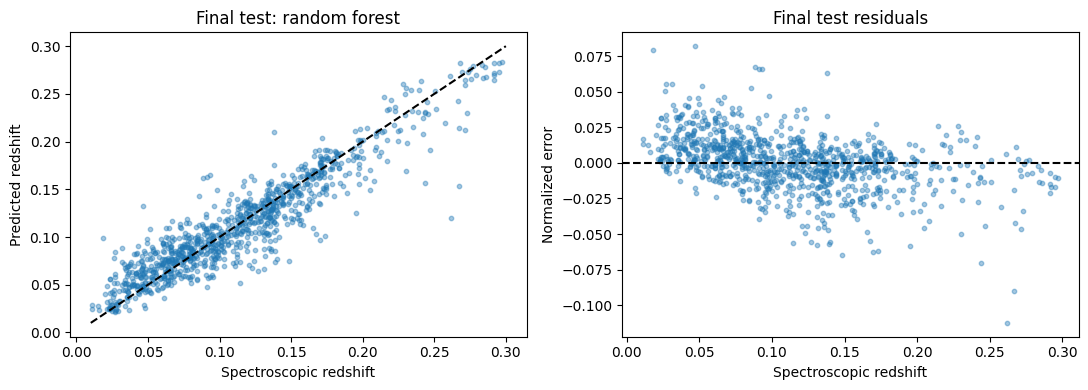

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Save the remaining development diagnostics.
leaf_comparison.to_csv(ROOT / 'results/leaf_size_validation.csv')
cv_comparison.to_csv(ROOT / 'results/cross_validation.csv')
importance_table.to_csv(ROOT / 'results/permutation_importance.csv', index=False)

# Save a final figure without changing the fitted model.
final_pred = test_predictions['Random forest']
final_delta = (final_pred - test['z_spec'].to_numpy()) / (1 + test['z_spec'].to_numpy())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(test['z_spec'], final_pred, s=10, alpha=0.4)
axes[0].plot([0.01, 0.30], [0.01, 0.30], 'k--')
axes[0].set(xlabel='Spectroscopic redshift', ylabel='Predicted redshift', title='Final test: random forest')
axes[1].scatter(test['z_spec'], final_delta, s=10, alpha=0.4)
axes[1].axhline(0, color='black', linestyle='--')
axes[1].set(xlabel='Spectroscopic redshift', ylabel='Normalized error', title='Final test residuals')
fig.tight_layout()
fig.savefig(ROOT / 'figures/final_test_diagnostics.png', dpi=180, bbox_inches='tight')
plt.show()

import shutil
final_archive = shutil.make_archive('/content/galaxy_photoz_complete_runtime', 'zip', ROOT)
try:
    from google.colab import files
    files.download(final_archive)
except ImportError:
    print('Complete runtime archive:', final_archive)


let’s inspect one actual tree from our trained forest, using its learned thresholds rather than invented numbers.

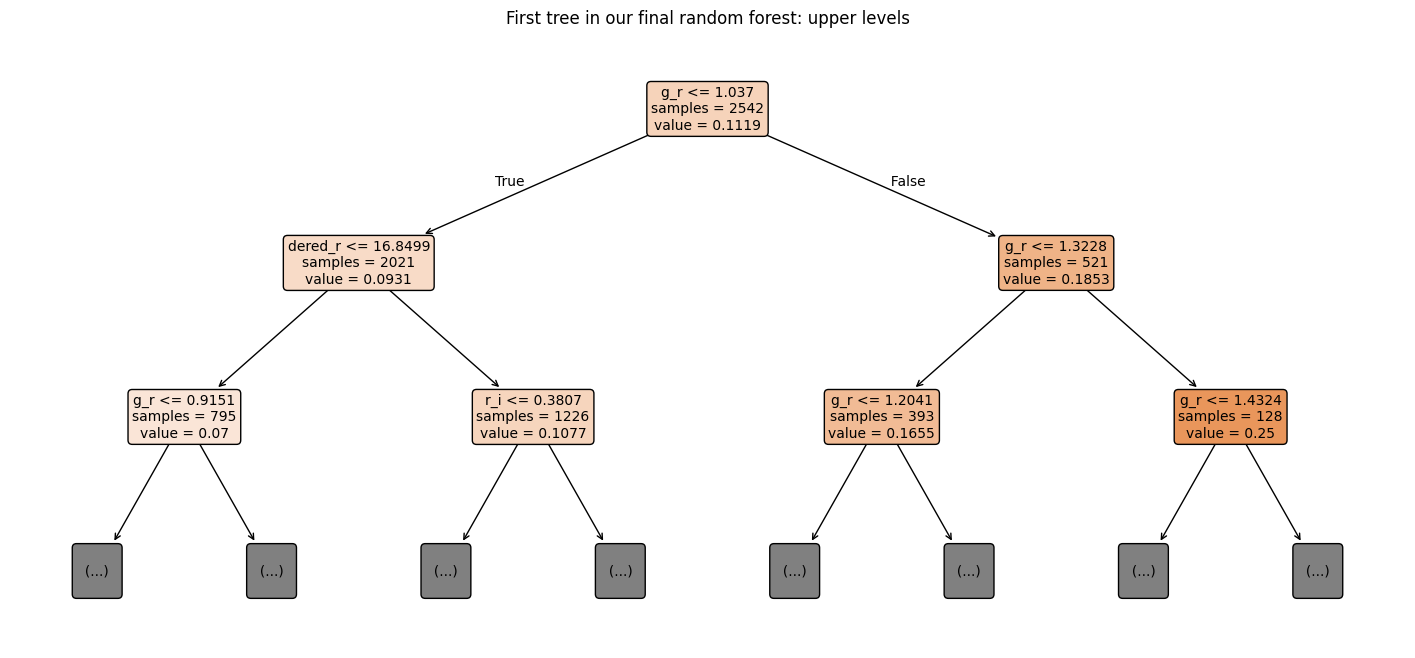

In [ ]:
from sklearn.tree import plot_tree

# First tree from the final trained random forest.
one_tree = final_models['Random forest'].estimators_[0]

fig, ax = plt.subplots(figsize=(18, 8))

plot_tree(
    one_tree,
    feature_names=FEATURES,
    max_depth=2,
    filled=True,
    rounded=True,
    impurity=False,
    precision=4,
    fontsize=10,
    ax=ax,
)

ax.set_title('First tree in our final random forest: upper levels')
plt.show()

### Understanding one trained tree in our random forest

Our final random forest contains **300 trained decision trees**. The following plot shows the upper levels of the first tree.

During training, each tree learned questions about our five photometric features: r-band magnitude, u−g, g−r, r−i, and i−z. It chose thresholds that reduced squared redshift errors within the resulting groups. Spectroscopic redshift (`z_spec`) supplied the training answers; it is never an input question.

#### Reading this tree

Start at the top and follow the branches:

- If a condition is **true**, go left.
- If it is **false**, go right.
- Continue until reaching a **leaf**, the endpoint with no further question.

In this tree, the first question is **g−r ≤ 1.037**. Galaxies satisfying it go left; the others go right.

On the left, the next question is **r ≤ 16.8499**. Remember that smaller magnitudes mean brighter light. On the right, the tree asks **g−r ≤ 1.3228**. A tree can reuse a feature at several splits and does not have to use all five features.

These thresholds were learned from our data. They are statistical rules, not physical boundaries between galaxy types.

#### What do the box labels mean?

- **`samples`**: the number of distinct training rows reaching that node in this tree’s bootstrap sample.
- **`value`**: their mean spectroscopic redshift, weighted by how often each row was drawn.

Our final forest was fitted on 4,000 development galaxies. Each tree drew 4,000 rows **with replacement**, so some galaxies appeared repeatedly and others were absent. This is why this tree’s root shows only **2,542 distinct rows**.

#### What is a leaf?

A **leaf gives the final prediction from one tree**. It has no further split condition or branches. Every galaxy reaching the same leaf receives the same prediction from that tree.

An internal box showing `value = 0.07` is not necessarily a prediction of 0.07: if it still has a question, the galaxy must continue down the tree.

Here, `max_depth=2` limits only the drawing. The gray **`(...)`** boxes indicate deeper branches that are hidden. The actual leaves are therefore not visible in this truncated plot.

#### How does the forest predict a test galaxy?

Each test galaxy follows one path through **each of the 300 trees**, reaching one leaf per tree. The forest averages those 300 leaf predictions to produce its final redshift estimate.

Only photometric features determine the paths. The test galaxy’s known spectroscopic redshift is used afterward to measure prediction error.

## 14. Conclusions, limitations, and learning checks

**What we established.** All 5,000 selected galaxies passed the declared broad audit. With 3,000 training, 1,000 validation, and 1,000 reserved test galaxies, the final forest achieved test MAE 0.015886 and NMAD 0.015489. It improved substantially over a constant median and linear regression. g−r was the feature whose shuffling most damaged validation accuracy.

**What remains unresolved.** Redshift-dependent bias persists. Unusual photometry can cause failures. The hash-selected Legacy spectroscopic sample is not representative of all galaxies. Adjacent colors share information, so permutation importance is not a causal decomposition. This experiment provides point predictions without calibrated individual uncertainties; it does not validate extrapolation, spatial transfer, or another survey.

**Explain in your own words:**
1. Why is a negative linear prediction a model failure for this selected sample?
2. Why can a forest with a larger training–validation gap still be preferable?
3. In five-fold cross-validation, why do we train five fresh models?
4. Why is shuffling g−r different from removing the g band and retraining?
5. Why can global bias be small while bin-wise biases are substantial?
6. Why does using the test results to tune require a new evaluation sample?
7. What physical and selection effects can make apparent brightness useful?

Possible future experiments include spatial holdouts, a separately declared photometric quality study, synthetic photometry to isolate spectral shifts, and calibrated prediction intervals. These are extensions, not claims established by this benchmark.

For GitHub, include this tutorial and your explanatory notes as you requested. Describe the measured results and limitations in the README; use the final **test** metrics for a résumé claim.

Additional method references: [random forests](https://scikit-learn.org/stable/modules/ensemble.html#random-forests), [cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html), and [permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html).